<a href="https://colab.research.google.com/github/JonaEmmOfCruz/Machine-learning/blob/main/Hands%20-%20on%206/Hands_on_6_kNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><strong>Clasificación de cáncer de mama mediante el algoritmo de K-vecinos más cercanos (KNN)</strong></h1>

<br>

Es un algoritmo de **aprendizaje automático supervisado**, **no paramétrico** y de **aprendizaje perezoso (** **lazy learning** **)** que realiza predicciones agrupando puntos por proximidad geométrica en un espacio métrico, asignando la clase a un nuevo dato mediante la **votación mayoritaria o moda** de sus vecinos más próximos sin generar un modelo matemático fijo de antemano

<br>

**¿De qué trata?**

Es la construcción e implementación paso a paso de un **pipeline de Machine Learning** para predecir si una muestra tumoral de masa mamaria es **benigna o maligna** a partir de descriptores morfológicos celulares a partir de características como el radio, textura, perímetro, área y suavidad, cubriendo desde la recolección y análisis del conjunto de datos **Wisconsin Diagnostic Breast Cancer**, pasando por el **escalamiento de características** y la exploración del **hiperparámetro k**, hasta la predicción y evaluación con **matriz de confusión y exactitud**

<br>

**Distancia Euclidiana:**
$$d(\mathbf{x}, \mathbf{x}_i) = \left( \sum_{j=1}^{p} (x_j - x_{ij})^2 \right)^{1/2}$$


**Distancia de Manhattan:**
$$d(\mathbf{x}, \mathbf{x}_i) = \sum_{j=1}^{p} |x_j - x_{ij}|$$


<h2><strong>Implementación en código</strong></h2>

<br>

<h3><strong>Importación de librerías</strong></h3>

In [1]:
# Módulo para montar y acceder a los archivos almacenados en Google Drive
from google.colab import drive

# Manejo de arreglos matriciales y operaciones numéricas
import numpy as np

# Estructuración y manipulación de tablas de datos (DataFrames / lectura de CSV)
import pandas as pd

# Creación de gráficos y visualización de resultados
import matplotlib.pyplot as plt

# Partición del conjunto de datos en subconjuntos de entrenamiento y prueba
from sklearn.model_selection import train_test_split

# Estandarización de características (media 0 y varianza unitaria)
from sklearn.preprocessing import StandardScaler

# Estimador y clasificador del algoritmo K-Nearest Neighbors
from sklearn.neighbors import KNeighborsClassifier

# Métricas de evaluación: matriz de confusión, visualización y exactitud global
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

<h3><strong>Montado de Google Drive para obtener el dataset</strong></h3>

In [11]:
# Monto el Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Defino la ruta del archivo
ruta = '/content/drive/MyDrive/Colab Notebooks/dataset/Breast_cancer_data.csv'

# Leo el archivo CSV
df = pd.read_csv(ruta)

# Inspección de las dimensiones del dataset cargado (filas, columnas)
print("Dimensiones totales del dataset:", df.shape)

# Muestro las primeras filas
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensiones totales del dataset: (569, 6)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0
1,20.57,17.77,132.90,1326.0,0.08474,0
2,19.69,21.25,130.00,1203.0,0.10960,0
3,11.42,20.38,77.58,386.1,0.14250,0
4,20.29,14.34,135.10,1297.0,0.10030,0


<h3><strong>Selección de Características y Codificación del Diagnóstico</strong></h3>

In [14]:
# Se toman todas las columnas del dataset excepto 'diagnosis' como matriz X
X = df.drop(columns=['diagnosis']).values

# Se selecciona la columna 'diagnosis' como vector de etiquetas objetivo y
y = df['diagnosis'].values

# Comprobación de las dimensiones de entrada y salida
print("Dimensiones de X (características):", X.shape)
print("Dimensiones de y (etiquetas):", y.shape)

Dimensiones de X (características): (569, 5)
Dimensiones de y (etiquetas): (569,)


<h3><strong>Revisión de Calidad de Datos</strong></h3>

In [16]:
# Verificación de tipos de datos de cada variable original
print("Tipos de datos:\\n", df.dtypes)

# Comprobación de existencia de valores nulos o vacíos en el dataset
print("\nValores faltantes por columna:\n", df.isna().sum())

# Conteo de registros repetidos
print("\nRegistros duplicados:", df.duplicated().sum())

# Resumen estadístico descriptivo completo de las variables
print("\nEstadísticas descriptivas:")
display(df.describe())

Tipos de datos:\n mean_radius        float64
mean_texture       float64
mean_perimeter     float64
mean_area          float64
mean_smoothness    float64
diagnosis            int64
dtype: object

Valores faltantes por columna:
 mean_radius        0
mean_texture       0
mean_perimeter     0
mean_area          0
mean_smoothness    0
diagnosis          0
dtype: int64

Registros duplicados: 0

Estadísticas descriptivas:


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,1.000000


<h3><strong>Scaatter plot del dataset</strong></h3>

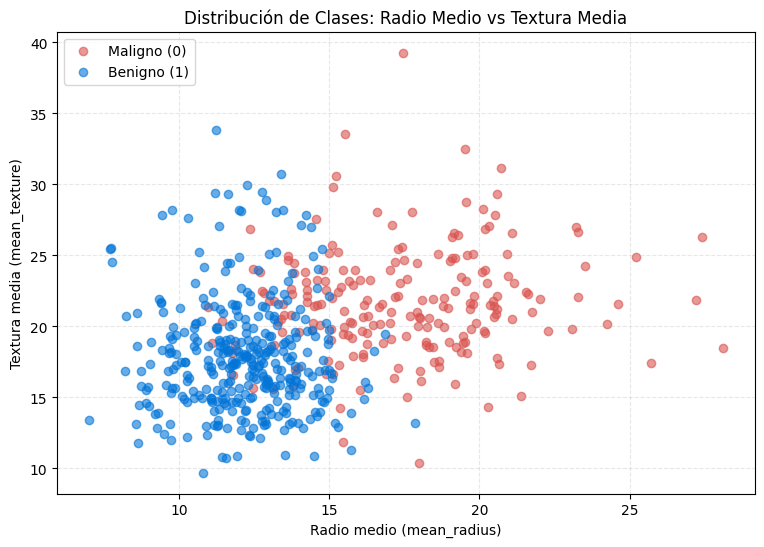

In [19]:
# Definición del tamaño de la figura en pulgadas
plt.figure(figsize=(9, 6))

# Trazado de las observaciones con diagnóstico maligno (diagnosis == 0)
plt.scatter( df.loc[df['diagnosis'] == 0, 'mean_radius'], df.loc[df['diagnosis'] == 0, 'mean_texture'], alpha=0.6, color='#d9534f', label='Maligno (0)' )

# Trazado de las observaciones con diagnóstico benigno (diagnosis == 1)
plt.scatter( df.loc[df['diagnosis'] == 1, 'mean_radius'], df.loc[df['diagnosis'] == 1, 'mean_texture'], alpha=0.6, color='#0275d8', label='Benigno (1)' )

# Configuración del título principal y etiquetas de los ejes cartesianos
plt.title("Distribución de Clases: Radio Medio vs Textura Media", fontsize=12)
plt.xlabel("Radio medio (mean_radius)", fontsize=10)
plt.ylabel("Textura media (mean_texture)", fontsize=10)

# Inclusión de la leyenda de clases y cuadrícula suave de fondo
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.3)

# Renderizado final del gráfico en pantalla
plt.show()

<h3><strong>División en Entrenamiento y Prueba</strong></h3>

In [22]:
# División de la matriz X y el vector y en 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, # Matriz de características
    y, # Vector de etiquetas objetivo
    test_size=0.20, # Proporción del 20% para el conjunto de prueba
    random_state=42 # Semilla pseudoaleatoria para asegurar reproducibilidad
    )

# Impresión de las dimensiones resultantes en el conjunto de entrenamiento
print("Dimensiones de X_train (entrenamiento):", X_train.shape)
print("Dimensiones de y_train (entrenamiento):", y_train.shape)

# Impresión de las dimensiones resultantes en el conjunto de prueba
print("\n Dimensiones de X_test (prueba):", X_test.shape)
print("Dimensiones de y_test (prueba):", y_test.shape)

Dimensiones de X_train (entrenamiento): (455, 5)
Dimensiones de y_train (entrenamiento): (455,)

 Dimensiones de X_test (prueba): (114, 5)
Dimensiones de y_test (prueba): (114,)


<h3><strong>Preprocesamiento con StandardScaler</strong></h3>

In [23]:
# Creación de la instancia del escalador estándar
scaler = StandardScaler()

# fit_transform(): calcula la media y la desviación estándar solo con X_train y lo escala
X_train_scaled = scaler.fit_transform(X_train)

# transform(): aplica los mismos parámetros calculados en X_train sobre X_test
X_test_scaled = scaler.transform(X_test)

# Inspección de las medias calculadas por característica durante el entrenamiento
print("Medias aprendidas por columna (train):\n", scaler.mean_)

# Inspección de las desviaciones estándar calculadas por característica
print("\nDesviaciones estándar aprendidas por columna (train):\n", scaler.scale_)

Medias aprendidas por columna (train):
 [1.41176352e+01 1.91850330e+01 9.18822418e+01 6.54377582e+02
 9.57440220e-02]

Desviaciones estándar aprendidas por columna (train):
 [3.53192761e+00 4.26131404e+00 2.42952845e+01 3.54552925e+02
 1.39076981e-02]


<h3><strong>Exploración del Número de Vecinos $k$</strong></h3>

<br>

El hiperparámetro $k$ determina cuántos vecinos participan en la votación mayoritaria3. Para observar su efecto sobre el desempeño, evaluamos los valores impares entre 1 y 29 (evitando empates al clasificar dos clases) y graficamos el comportamiento de la exactitud (accuracy)

,k,accuracy
0,1,0.929825
1,3,0.903509
2,5,0.929825
3,7,0.956140
4,9,0.956140
5,11,0.964912
6,13,0.956140
7,15,0.956140
8,17,0.956140
9,19,0.964912


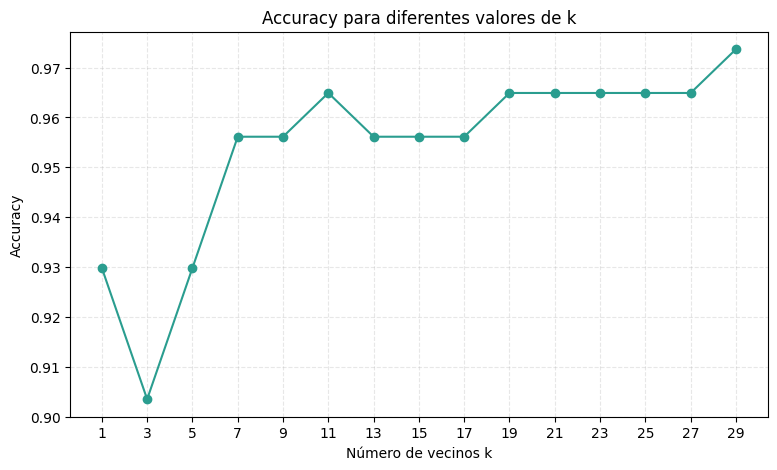

In [24]:
# Rango de valores impares de 1 a 29 para k
valores_k = range(1, 30, 2)

# Lista para almacenar la exactitud de cada modelo
accuracies = []

for k in valores_k:
  # 1. Creación del clasificador KNN con el k de la iteración actual
  modelo = KNeighborsClassifier(n_neighbors=k)

  # 2. Ajuste del modelo con los datos de entrenamiento escalados
  modelo.fit(X_train_scaled, y_train)

  # 3. Predicción sobre las observaciones de prueba
  predicciones = modelo.predict(X_test_scaled)

  # 4. Cálculo de la exactitud
  accuracy_k = accuracy_score(y_test, predicciones)

  # 5. Registro del accuracy obtenido
  accuracies.append(accuracy_k)

# Estructuración de los resultados en un DataFrame para visualizarlos en tabla
tabla_k = pd.DataFrame({ "k": list(valores_k), "accuracy": accuracies })

# Despliegue de la tabla comparativa
display(tabla_k)

# Generación del gráfico de exactitud frente a k
plt.figure(figsize=(9, 5))
plt.plot(tabla_k["k"],
tabla_k["accuracy"], marker="o", color="#2a9d8f")
plt.title("Accuracy para diferentes valores de k")
plt.xlabel("Número de vecinos k")
plt.ylabel("Accuracy")
plt.xticks(tabla_k["k"])
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

<h3><strong>Selección de $k$ y Ajuste del Modelo Final</strong></h3>

In [26]:
# Identificación del valor máximo de exactitud alcanzado
mejor_accuracy = tabla_k["accuracy"].max()

# Selección del menor k que haya obtenido esa exactitud máxima
mejor_k = int(tabla_k.loc[tabla_k["accuracy"] == mejor_accuracy, "k"].min())
print(f"Mejor k seleccionado: {mejor_k} (Accuracy observado: {mejor_accuracy:.4f})")

# Instanciación del clasificador definitivo
knn = KNeighborsClassifier(n_neighbors=mejor_k)

# Ajuste del modelo (almacenamiento en memoria de las 455 muestras de train)
knn.fit(X_train_scaled, y_train)
print(f"Clasificador final ajustado con k = {mejor_k}.")

Mejor k seleccionado: 29 (Accuracy observado: 0.9737)
Clasificador final ajustado con k = 29.


<h3><strong>Inspección del Vecindario con kneighbors()</strong></h3>

In [30]:
# Se toma la primera observación del conjunto de prueba y se mantiene en formato 2D (1 fila, 5 columnas)
x_consulta = X_test_scaled[[0]]

# Se consultan las distancias euclidianas y los índices de sus vecinos en el conjunto de entrenamiento
distancias, indices = knn.kneighbors(x_consulta, n_neighbors=mejor_k)

# Se aplanan los arrays resultantes a una dimensión para poder crear el DataFrame
indices_planos = indices.flatten()
distancias_planas = distancias.flatten()

# Se obtienen las clases reales de dichos vecinos indexando directamente el array y_train
clases_vecinos = y_train[indices_planos]

# Se estructura una tabla descriptiva para analizar el vecindario
vecinos = pd.DataFrame({
    "Distancia": distancias_planas,
    "Clase": clases_vecinos,
    "Diagnóstico": [ "Maligno" if clase == 0 else "Benigno" for clase in clases_vecinos ]
})

# Despliegue de los primeros vecinos más próximos
print("Vecinos más cercanos de la primera observación de prueba:")
display(vecinos.head(10))

Vecinos más cercanos de la primera observación de prueba:


,Distancia,Clase,Diagnóstico
0,0.368008,0,Maligno
1,0.379635,1,Benigno
2,0.384871,1,Benigno
3,0.424074,1,Benigno
4,0.431459,1,Benigno
5,0.457846,1,Benigno
6,0.511308,1,Benigno
7,0.511370,1,Benigno
8,0.515433,1,Benigno
9,0.523873,1,Benigno


<h3><strong>Predicción sobre el Conjunto de Prueba</strong></h3>

In [33]:
# Clasificación de la totalidad de las muestras de prueba
y_pred = knn.predict(X_test_scaled)

# Diccionario semántico para interpretar los códigos numéricos
nombre_clase = { 0: "Maligno", 1: "Benigno" }

# Creación de una tabla comparativa con los diagnósticos reales vs predichos
resultados = pd.DataFrame({ "Diagnóstico real": [nombre_clase[clase] for clase in y_test], "Diagnóstico predicho": [nombre_clase[clase] for clase in y_pred] })

# Identificación de aciertos y errores en cada predicción
resultados["Resultado"] = [ "✅ Acierto" if real == pred else "❌ Error" for real, pred in zip(resultados["Diagnóstico real"], resultados["Diagnóstico predicho"]) ]

# Visualización de las primeras 10 comparativas
print("Primeras 10 predicciones del conjunto de prueba:")
display(resultados.head(10))

Primeras 10 predicciones del conjunto de prueba:


,Diagnóstico real,Diagnóstico predicho,Resultado
0,Benigno,Benigno,✅ Acierto
1,Maligno,Maligno,✅ Acierto
2,Maligno,Maligno,✅ Acierto
3,Benigno,Benigno,✅ Acierto
4,Benigno,Benigno,✅ Acierto
5,Maligno,Maligno,✅ Acierto
6,Maligno,Maligno,✅ Acierto
7,Maligno,Maligno,✅ Acierto
8,Benigno,Benigno,✅ Acierto
9,Benigno,Benigno,✅ Acierto


<h3><strong>Evaluación de la Técnica</strong></h3>

<br>

Fundamento: Se evalúa cuantitativamente la capacidad de generalización del clasificador mediante dos herramientas410:Matriz de Confusión: Contrasta las clases clínicas verdaderas (filas) frente a las inferidas por KNN (columnas) para examinar falsos positivos y falsos negativos410.Exactitud (Accuracy): Proporción total de aciertos sobre el universo de prueba10: $$\operatorname{Accuracy} = \frac{\text{Predicciones Correctas}}{\text{Total de Muestras Evaluadas}} = \frac{VP + VN}{VP + VN + FP + FN}$$

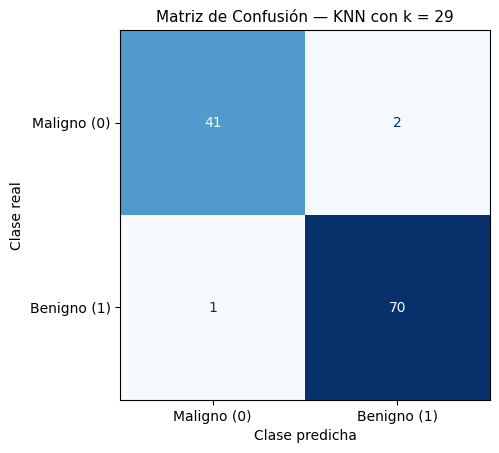

Accuracy final del modelo: 0.9737
Accuracy porcentual: 97.37%


In [36]:
# 1. Cálculo de la matriz de confusión estableciendo el orden [0: Maligno, 1: Benigno]
cm = confusion_matrix( y_test, y_pred, labels=[0, 1] )

# 2. Configuración gráfica de la matriz con mapa de calor azul
disp = ConfusionMatrixDisplay( confusion_matrix=cm, display_labels=["Maligno (0)", "Benigno (1)"] )
disp.plot(cmap="Blues", colorbar=False)

# 3. Personalización estética del gráfico
plt.title(f"Matriz de Confusión — KNN con k = {mejor_k}", fontsize=11)
plt.xlabel("Clase predicha", fontsize=10)
plt.ylabel("Clase real", fontsize=10)
plt.grid(False)
plt.show()

# 4. Cálculo formal de la métrica de exactitud global
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy final del modelo: {accuracy:.4f}")
print(f"Accuracy porcentual: {accuracy * 100:.2f}%")